# $\text{Brushing up the basics}$

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint


G=100
M=40
R=1
m=10
δ=100

k=G*M

def V(x,y):
    r=np.sqrt(x**2+y**2)

    return -k*m/r

def KE(vx,vy):

    v=np.sqrt(vx**2+vy**2)

    return 0.5*m*(v**2)

def U(sol):
    return KE(sol.T[2],sol.T[3])+V(sol.T[0],sol.T[1])


def acc(state , t):
    x,y,vx,vy=state

    r=np.sqrt(x**2+y**2)
    θ=np.arctan2(y,x)

    a=-(k/r**2)-(δ/r**3)


    if r>R :
        ax=a*np.cos(θ)
        ay=a*np.sin(θ)
        return (vx,vy,ax,ay)
    else:
        ax=0
        ay=0
        return (vx,vy,ax,ay)

    

t=np.linspace(0,10**4,1000000)

state0=(10,8,10,-20)

sol=odeint(acc,state0,t=t,rtol=1e-9, atol=1e-9)

(-627.3404443939983, -622.091346670592)

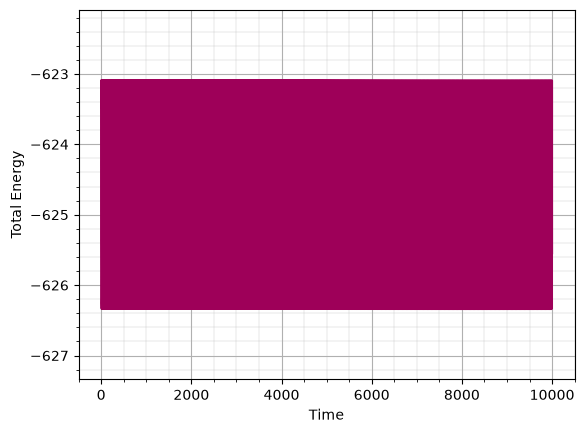

In [37]:
plt.plot(t,U(sol),color="#9e0059",lw=1.5)
plt.grid(True)
plt.minorticks_on()
plt.grid(which="minor",lw=0.2)
plt.xlabel("Time")
plt.ylabel("Total Energy")
plt.ylim(np.min(U(sol))-1,np.max(U(sol))+1)

(-100.0, 100.0)

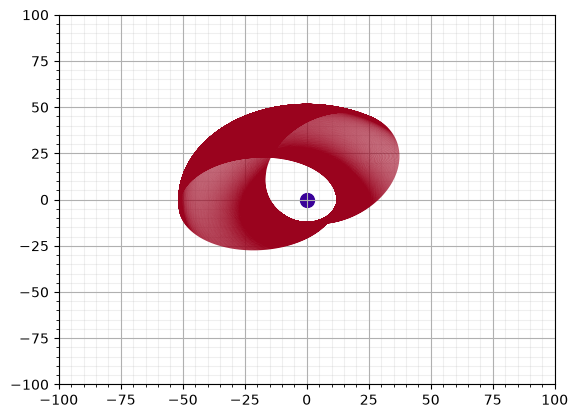

In [38]:
plt.plot(sol.T[0],sol.T[1],color="#9a031e",lw=0.1)
plt.grid(True)
plt.minorticks_on()
plt.grid(which="minor",alpha=0.2)
plt.scatter(0,0,s=100,color="#390099")

plt.xlim(-100,100)
plt.ylim(-100,100)



# $\text{Mercury orbit analysis from JPL/NASA data}$ 

In [39]:
import pandas as pd

# Define clean column names to override the messy header string
column_names = ['JDTDB', 'Calendar_Date', 'X', 'Y', 'Z', 'VX', 'VY', 'VZ', 'LT', 'RG', 'RR']

# Read the file line-by-line to isolate only the raw data numbers
data_lines = []
with open("/home/suparnajit2005/GitHub/Classical_mechanics_simulations/Central-force-motion/Data/JPL/horizons_results.csv", "r") as f:
    in_data_zone = False
    for line in f:
        if "$$EOE" in line:
            break
        if in_data_zone:
            # Strip trailing commas and whitespace blocks
            cleaned_line = line.strip().rstrip(',')
            if cleaned_line:
                data_lines.append(cleaned_line.split(','))
        if "$$SOE" in line:
            in_data_zone = True

# Construct the clean DataFrame directly from parsed rows
df = pd.DataFrame(data_lines, columns=column_names)

# Strip out trailing spaces from text fields and convert columns to proper types
df['Calendar_Date'] = df['Calendar_Date'].str.strip()

numeric_cols = ['JDTDB', 'X', 'Y', 'Z', 'VX', 'VY', 'VZ', 'LT', 'RG', 'RR']
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric)

# Preview your flawlessly formatted dataset
print(df.head(31))

Data_matrix=df.to_numpy()

# Time Initialisation
t0=np.ones_like(Data_matrix.T[0])*np.min(Data_matrix.T[0])
t_days=Data_matrix.T[0]-t0

# State Initialisation
state=np.array([Data_matrix.T[2].astype(float),Data_matrix.T[3].astype(float),Data_matrix.T[4].astype(float),Data_matrix.T[5].astype(float),Data_matrix.T[6].astype(float),Data_matrix.T[7].astype(float)])


        JDTDB                   Calendar_Date             X             Y  \
0   2461336.5  A.D. 2026-Oct-23 00:00:00.0000  5.305214e+07 -1.622983e+07   
1   2461337.5  A.D. 2026-Oct-24 00:00:00.0000  5.360814e+07 -1.252248e+07   
2   2461338.5  A.D. 2026-Oct-25 00:00:00.0000  5.386810e+07 -8.746150e+06   
3   2461339.5  A.D. 2026-Oct-26 00:00:00.0000  5.381644e+07 -4.919395e+06   
4   2461340.5  A.D. 2026-Oct-27 00:00:00.0000  5.343842e+07 -1.062991e+06   
5   2461341.5  A.D. 2026-Oct-28 00:00:00.0000  5.272050e+07  2.799979e+06   
6   2461342.5  A.D. 2026-Oct-29 00:00:00.0000  5.165081e+07  6.644060e+06   
7   2461343.5  A.D. 2026-Oct-30 00:00:00.0000  5.021969e+07  1.044143e+07   
8   2461344.5  A.D. 2026-Oct-31 00:00:00.0000  4.842022e+07  1.416197e+07   
9   2461345.5  A.D. 2026-Nov-01 00:00:00.0000  4.624890e+07  1.777352e+07   
10  2461346.5  A.D. 2026-Nov-02 00:00:00.0000  4.370631e+07  2.124212e+07   
11  2461347.5  A.D. 2026-Nov-03 00:00:00.0000  4.079772e+07  2.453257e+07   

In [40]:
# ==============================================================================
# MERCURY PHYSICAL CONSTANTS (Source: NASA JPL Horizons Ephemeris System)
# ==============================================================================

# --- Mercury Absolute Physical Constants ---
MERCURY_RADIUS_MEAN_KM = 2439.4       # Volumetric mean radius in km
MERCURY_RADIUS_EQ_KM   = 2440.53      # Equatorial radius (Re) in km
MERCURY_DENSITY_G_CM3  = 5.427        # Density in g/cm^3
MERCURY_VOLUME_KM3     = 6.085e10     # Volume in km^3 (derived from 6.085 x 10^10)
MERCURY_SURFACE_G_MS2  = 3.701        # Equatorial surface gravity in m/s^2
MERCURY_ESCAPE_VEL_KMS = 4.435        # Escape velocity in km/s

# --- Orbital Mechanics Constants ---
MERCURY_GM_KM3_S2      = 22031.86855  # Standard gravitational parameter (μ) in km^3/s^2
SUN_MERCURY_MASS_RATIO = 6023682.0    # Mass ratio of the Sun to Mercury (M_sun / M_mercury)
MERCURY_MEAN_VEL_KMS   = 47.362       # Mean orbital velocity in km/s
MERCURY_ORBIT_PERIOD_D = 87.969257    # Sidereal orbital period in solar days

# --- Rotational Constants ---
MERCURY_ROT_PERIOD_D   = 58.6463      # Sidereal rotation period in solar days
MERCURY_ROT_RATE_RAD_S = 1.24001e-6   # Sidereal rotation rate in rad/s

# ==============================================================================
# DYNAMIC MASS & G DERIVATIONS (Auto-converted to Standard SI / MKS Units)
# ==============================================================================

# 1. Absolute Masses (in kg)
MERCURY_MASS_KG = 3.302e23            # 3.302 x 10^23 kg
SUN_MASS_KG     = MERCURY_MASS_KG * SUN_MERCURY_MASS_RATIO

# 2. Standard Gravitational Parameter in SI Units (m^3 / s^2)
MERCURY_GM_M3_S2 = MERCURY_GM_KM3_S2 * 1e9

# 3. Universal Gravitational Constant 'G' Derived Dynamically from File State
# Formula: G = GM / M
G_SI = MERCURY_GM_M3_S2 / MERCURY_MASS_KG

# --- Print Validation Check ---
print(f"--- NASA Horizons Constants Imported Successfully ---")
print(f"Mercury Mass : {MERCURY_MASS_KG:.3e} kg")
print(f"Sun Mass     : {SUN_MASS_KG:.3e} kg")
print(f"Derived G    : {G_SI:.7e} m^3/(kg*s^2)")


--- NASA Horizons Constants Imported Successfully ---
Mercury Mass : 3.302e+23 kg
Sun Mass     : 1.989e+30 kg
Derived G    : 6.6722800e-11 m^3/(kg*s^2)


In [41]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from scipy.integrate import solve_ivp


  
G=G_SI
M=SUN_MASS_KG

m=MERCURY_MASS_KG


k=G*M*(1e-9)

def V(x,y,z):
    r=np.sqrt(x**2+y**2+z**2)

    return -k*m/r

def KE(vx,vy,vz):

    v=np.sqrt(vx**2+vy**2+vz**2)

    return 0.5*m*(v**2)

def U(sol):
    return np.array([KE(sol.y[3],sol.y[4],sol.y[5])+V(sol.y[0],sol.y[1],sol.y[2]),KE(sol.y[3],sol.y[4],sol.y[5]),V(sol.y[0],sol.y[1],sol.y[2])])


def acc(t,state):
    x,y,z,vx,vy,vz=state
    
    r=(x**2+y**2+z**2)**0.5
    
    a=-(k/r**3)-(1000/r**4)

    ax=a*x
    ay=a*y
    az=a*z
    return (vx,vy,vz,ax,ay,az)

        

    
days=31
t_span=(0,days*24*3600)
t_eval=np.linspace(0,max(t_span),31)

state0=(state[0][0],state[1][0],state[2][0],state[3][0],state[4][0],state[5][0])

#sol=odeint(acc,state0,t=t)
sol=solve_ivp(acc,t_span,state0,method='DOP853',t_eval=t_eval)


In [42]:
sol

  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  8.928e+04 ...  2.589e+06  2.678e+06]
        y: [[ 5.305e+07  5.362e+07 ... -4.220e+07 -4.537e+07]
            [-1.623e+07 -1.240e+07 ...  2.403e+07  2.080e+07]
            ...
            [ 4.244e+01  4.337e+01 ... -3.513e+01 -3.703e+01]
            [ 2.184e+01  2.269e+01 ... -1.488e+01 -1.628e+01]]
      sol: None
 t_events: None
 y_events: None
     nfev: 110
     njev: 0
      nlu: 0

# $\text{Error-Analysis:}$

$\text{Difference in coordinate between the JPL data and simulation data }$

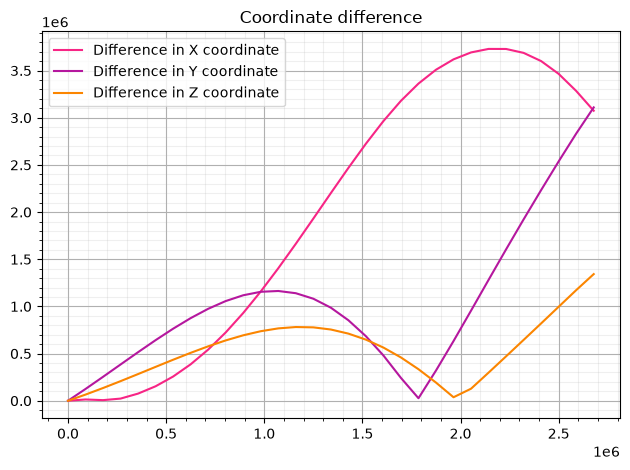

In [43]:
δx=abs(sol.y[0]-state[0])
δy=abs(sol.y[1]-state[1])
δz=abs(sol.y[2]-state[2])
plt.rcParams['figure.dpi'] = 100
plt.title("Coordinate difference")
plt.minorticks_on()
plt.grid(which="minor",alpha=0.2)
plt.grid(which="major")
plt.plot(t_eval,δx,color="#f72585",label="Difference in X coordinate")
plt.plot(t_eval,δy,color="#b5179e",label="Difference in Y coordinate")
plt.plot(t_eval,δz,color="#fb8500",label="Difference in Z coordinate")
plt.legend()
plt.tight_layout()
plt.savefig("Coordinate-difference.svg")


$\text{Energy-Analysis:}$

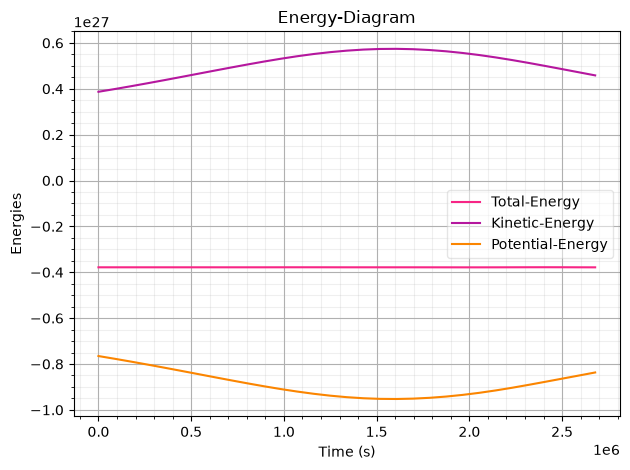

In [44]:
plt.title("Energy-Diagram")
plt.xlabel("Time (s)")
plt.ylabel("Energies")
plt.minorticks_on()
plt.grid(which="minor",alpha=0.2)
plt.grid(which="major")
plt.plot(t_eval,U(sol)[0],color="#f72585",label="Total-Energy")
plt.plot(t_eval,U(sol)[1],color="#b5179e",label="Kinetic-Energy")
plt.plot(t_eval,U(sol)[2],color="#fb8500",label="Potential-Energy")
plt.legend(framealpha=0.5,shadow=False)
plt.tight_layout()
plt.savefig("Energy-diagram.svg")

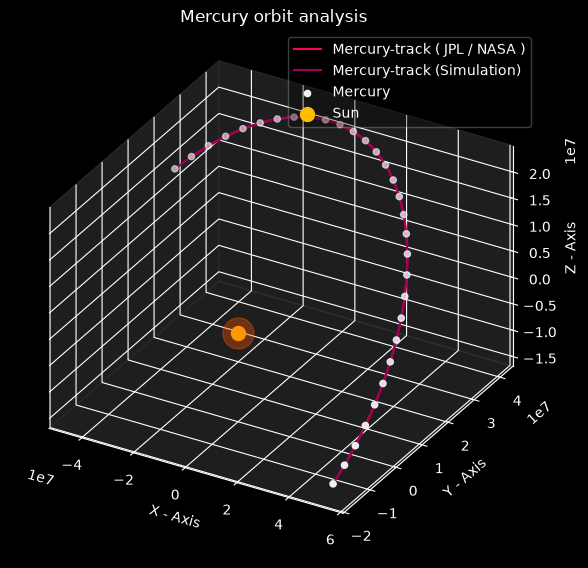

In [45]:
from matplotlib import pyplot as plt


#Plotting

with plt.style.context("dark_background"):

    fig=plt.figure(figsize=(6,6))
    ax=fig.add_subplot(projection="3d")
    ax.set_title("Mercury orbit analysis")
    ax.set_xlabel("X - Axis")
    ax.set_ylabel("Y - Axis")
    ax.set_zlabel("Z - Axis")
    # Set the background panel colors with a low alpha (e.g., 0.1 for 10% opacity)
    # Format is (Red, Green, Blue, Alpha)
    ax.xaxis.set_pane_color((0.2, 0.2, 0.2, 0.6))
    ax.yaxis.set_pane_color((0.2, 0.2, 0.2, 0.6))
    ax.zaxis.set_pane_color((0.2, 0.2, 0.2, 0.6))
    ax.set_proj_type('ortho')


    ax.plot(state[0],state[1],state[2],lw=1.5,color="#FF0054",label="Mercury-track ( JPL / NASA )")
    ax.plot(sol.y[0],sol.y[1],sol.y[2],color="#9E0059",label="Mercury-track (Simulation)")
    ax.scatter(sol.y[0],sol.y[1],sol.y[2],color="#F3F3F3",label="Mercury")
    ax.scatter(0,0,0,color="#FFBD00",s=100,label="Sun")
    ax.scatter(0,0,0,color="#FF5400",s=500,alpha=0.6)
    ax.legend(framealpha=0.3,shadow=False,loc=1)
    plt.tight_layout()
    plt.savefig("Mercury-orbit-analysis.svg")
